In [22]:
from dotenv import load_dotenv
from pathlib import Path
from os import getenv
from sys import path
import pandas as pd
import time
import numpy as np
import matplotlib.pyplot as plt
import requests

In [3]:
# constants
PROJECT_PATH = Path.cwd().parent.parent
ENV_FILE = "ml.env"

In [86]:
# include project path in sys.path such that we can access resources from app folder.
path.insert(0, str(PROJECT_PATH))
from app.core.model_loader import load_model
from app.utils.utils import cut_movenet_frames

In [5]:
load_dotenv(PROJECT_PATH / ENV_FILE)
assert(getenv("MLFLOW_TRACKING_INSECURE_TLS") is not None)
assert(getenv("MLFLOW_TRACKING_USERNAME") is not None)
assert(getenv("MLFLOW_TRACKING_PASSWORD") is not None)
assert(getenv("MLFLOW_TRACKING_URI") is not None)

In [6]:
ml_tracking_uri = getenv("MLFLOW_TRACKING_URI")
print(ml_tracking_uri)

https://172.27.62.170:5001/


In [7]:
# load cutter model, movenet->2d model, and 2d -> 3d model
cutter = load_model("frame_cutter")
movenet_to_2d = load_model("movenet_to_2d_kinect")
two_d_to_3d = load_model("2d_kinect_to_3d_kinect")

/Users/pettergustafsson/study/4DT907/project_dir/ml/api/venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/pettergustafsson/study/4DT907/project_dir/ml/api/venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/Users/pettergustafsson/study/4DT907/project_dir/ml/api/venv/lib/python3.11/site-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host '172.27.62.170'. Adding certificate verification is strongly advised. See: https://urllib

In [8]:
# load movenet csv file
file_name = "research/data/A1.csv"
try:
    a1 = pd.read_csv(PROJECT_PATH / file_name)
except FileNotFoundError as e:
    print(f"{file_name} was not found: {e}")


In [87]:
RUNS = 1000

cutter_times = np.zeros(RUNS)
movenet_to_2d_times = np.zeros(RUNS)
two_d_to_3d_times = np.zeros(RUNS)

for _ in range(10):
    _ = cutter.predict(a1)

for i in range(RUNS):
    start = time.perf_counter()
    _ = cutter.predict(a1)
    cutter_times[i] = time.perf_counter() - start

cutted_frames = cutter.predict(a1)
a1_cutted = cut_movenet_frames(a1, cutted_frames)

for _ in range(10):
    twod_kinect = movenet_to_2d.predict(a1)

for i in range(RUNS):
    start = time.perf_counter()
    twod_kinect = movenet_to_2d.predict(a1_cutted)
    movenet_to_2d_times[i] = time.perf_counter() - start


twod_kinect = movenet_to_2d.predict(a1_cutted)

for _ in range(10):
    _ = two_d_to_3d.predict(twod_kinect)

# Measure 2D -> 3D
for i in range(RUNS):
    start = time.perf_counter()
    _ = two_d_to_3d.predict(twod_kinect)
    two_d_to_3d_times[i] = time.perf_counter() - start

In [88]:
print(f"cutter: {cutter_times[0:10]}")
print(f"\nmovenet to 2d: {movenet_to_2d_times[0:10]}")
print(f"\n2d to 3d: {two_d_to_3d_times[0:10]}")

cutter: [0.02254242 0.02192808 0.02144862 0.02098858 0.02119146 0.02110287
 0.02065558 0.02037279 0.0208745  0.02103621]

movenet to 2d: [0.00120367 0.00113267 0.00132025 0.00120354 0.00114092 0.00112046
 0.001091   0.00109975 0.00110108 0.00110421]

2d to 3d: [0.027457   0.02791383 0.02811104 0.02848296 0.02880546 0.02736308
 0.02779379 0.025951   0.05674333 0.03384804]


In [89]:
cutter_mean_std = (cutter_times.mean(), cutter_times.std())
movenet_to_2d_mean_std = (movenet_to_2d_times.mean(), movenet_to_2d_times.std())
twod_to_3d_mean_std = (two_d_to_3d_times.mean(), two_d_to_3d_times.std())

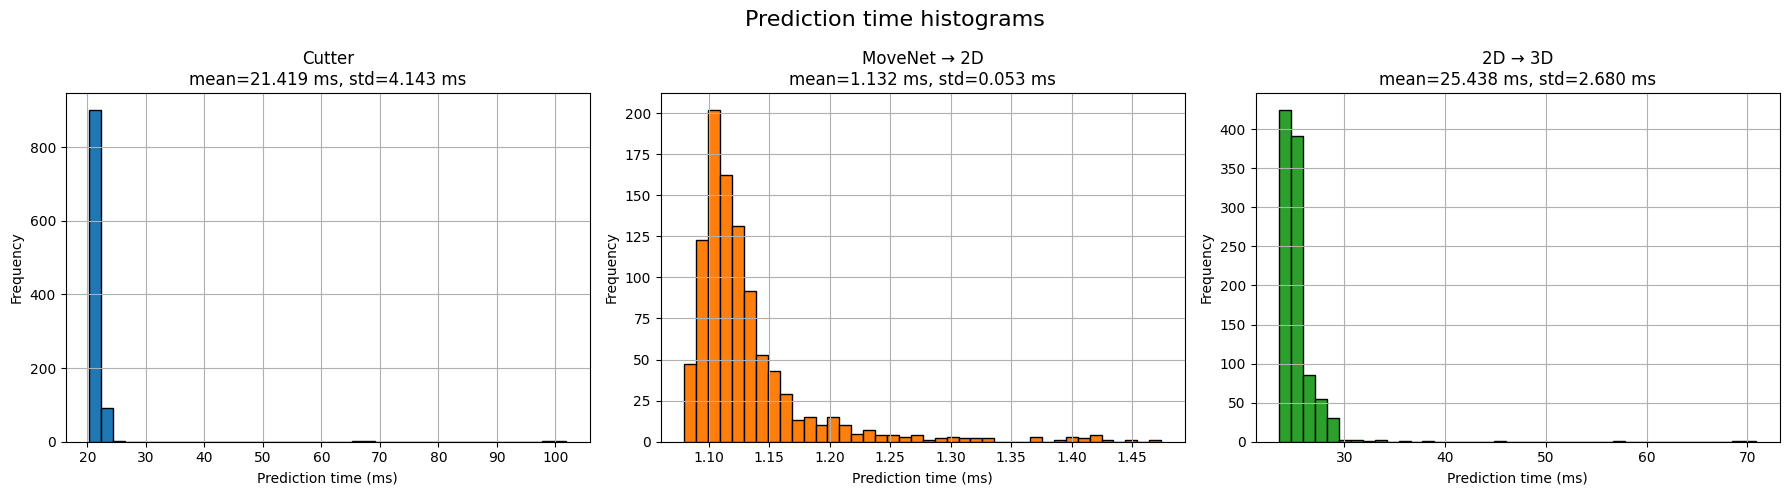

In [90]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

histograms = [
    ("Cutter", cutter_times, cutter_mean_std, "tab:blue"),
    ("MoveNet → 2D", movenet_to_2d_times, movenet_to_2d_mean_std, "tab:orange"),
    ("2D → 3D", two_d_to_3d_times, twod_to_3d_mean_std, "tab:green"),
]

for ax, (title, times, mean_std, color) in zip(axes, histograms):
    mean, std = mean_std

    ax.hist(times * 1000, bins=40, color=color, edgecolor="black")
    ax.set_title(f"{title}\nmean={mean * 1000:.3f} ms, std={std * 1000:.3f} ms")
    ax.set_xlabel("Prediction time (ms)")
    ax.set_ylabel("Frequency")
    ax.grid(True)

fig.suptitle("Prediction time histograms", fontsize=16)
plt.tight_layout()
plt.show()

In [91]:
total_time = cutter_times + movenet_to_2d_times + two_d_to_3d_times
print(f"total times: {total_time[0:10]}")

total times: [0.05120308 0.05097458 0.05087992 0.05067508 0.05113784 0.04958642
 0.04954038 0.04742354 0.07871892 0.05598846]


In [92]:
# test connection to FastAPI
PORT = 8000
URL = f"http://localhost:{PORT}/health"

try:
    response = requests.get(URL, timeout=5)

    print("Status code:", response.status_code)

    if response.ok:
        print("Connection successful")
        print("Response:", response.text)
    else:
        print("Server returned an error")
        print("Response:", response.text)

except requests.exceptions.Timeout:
    print("Request timed out")

except requests.exceptions.ConnectionError:
    print("Could not connect to the server")

except requests.exceptions.RequestException as e:
    print("Request failed:", e)

Status code: 200
Connection successful
Response: {"status":"ok"}


In [93]:
service_times = np.zeros(RUNS)       # server-side measured time

file_name = "A1.csv"
url = f"http://localhost:8000/datasets/csv/{file_name}"

# Optional warm-up
for _ in range(10):
    response = requests.get(url, timeout=30)
    _ = response.content

for i in range(RUNS):
    start = time.perf_counter()

    response = requests.get(url, timeout=30)
    _ = response.content   # force full StreamingResponse body to be received

    stop = time.perf_counter()

    time_measurement = stop - start

    service_times[i] = time_measurement

    if response.status_code != 200:
        print(f"Run {i}: failed with status code {response.status_code}")

In [94]:
print(f"endpoint times: {service_times[0:10]}")

endpoint times: [0.06190942 0.06263238 0.06589396 0.07405104 0.07452629 0.12544275
 0.08308283 0.09690046 0.08302571 0.08261275]


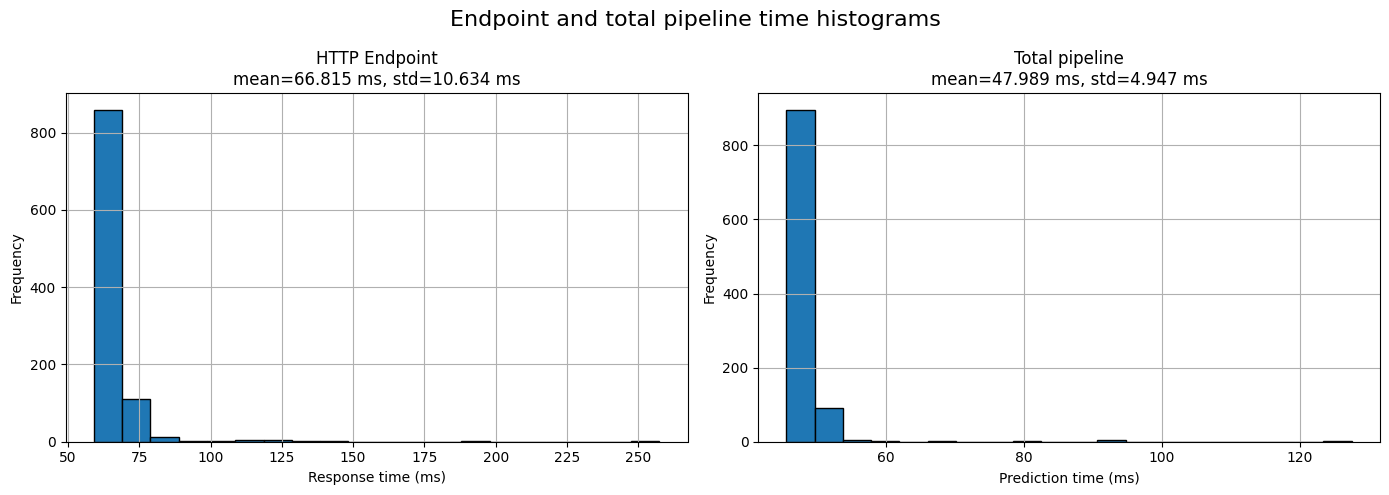

Endpoint mean: 66.815 ms, std=10.634 ms
Total pipeline mean: 47.989 ms, std=4.947 ms


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

endpoint_times_ms = service_times * 1000

total_times_ms = total_time * 1000

endpoint_mean = np.mean(endpoint_times_ms)
endpoint_std = np.std(endpoint_times_ms)

total_mean = np.mean(total_times_ms)
total_std = np.std(total_times_ms)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Endpoint and total pipeline time histograms", fontsize=16)

# Endpoint plot
axes[0].hist(endpoint_times_ms, bins=20, edgecolor="black")
axes[0].set_title(
    f"HTTP Endpoint\n"
    f"mean={endpoint_mean:.3f} ms, std={endpoint_std:.3f} ms"
)
axes[0].set_xlabel("Response time (ms)")
axes[0].set_ylabel("Frequency")
axes[0].grid(True)

# Total pipeline plot
axes[1].hist(total_times_ms, bins=20, edgecolor="black")
axes[1].set_title(
    f"Total pipeline\n"
    f"mean={total_mean:.3f} ms, std={total_std:.3f} ms"
)
axes[1].set_xlabel("Prediction time (ms)")
axes[1].set_ylabel("Frequency")
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Endpoint mean: {endpoint_mean:.3f} ms, std={endpoint_std:.3f} ms")
print(f"Total pipeline mean: {total_mean:.3f} ms, std={total_std:.3f} ms")

In [99]:
# Enpoint mean, pipeline mean quotient

quo = total_mean / endpoint_mean
print(f"prediction time divided by full pipeline in endpoint: {quo}")

prediction time divided by full pipeline in endpoint: 0.7182253165607776
